HASTS206 Assignment 1 – Group 3
Household access to clean cooking energy in Zimbabwe: Python analysis of the digital pilot
Scope. This notebook cleans and analyses the raw KoBoToolbox export from a pilot of 34 simulated household responses (urban and rural). The pilot tests the proposed workflow (form → Python → Power BI). Its results describe the pilot records only and cannot establish national prevalence.

Source label. Simulated household responses submitted through the actual KoBoToolbox form by the five enumerators. No names, phone numbers, precise addresses or account details were collected.

How to rerun. Open this notebook from the repository (the notebooks/ folder or the repository root), then Kernel → Restart & Run All. Paths are relative; the raw export in data/raw/ is read and never modified. Outputs are written to outputs/.


Section	Content
1	Load and inspect the raw export
2	Quality checks and quality log (before / after)
3	Cleaning rules and tidy case-level file
4	Indicator definitions and results (overall and by domain)
5	Charts
6	Weighting demonstration (simulated, separate from the pilot)
7	Exports for Power BI, benchmark table, reconciliation helper


In [2]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

# ---- Relative paths: work from the repository root or from notebooks/ ----
HERE = Path.cwd().resolve()
ROOT = HERE if (HERE / "data" / "raw").exists() else HERE.parent
RAW_DIR = ROOT / "data" / "raw"
OUT = ROOT / "outputs"
FIG = OUT / "figures"
for p in (OUT, FIG):
    p.mkdir(parents=True, exist_ok=True)

RAW_FILE = sorted(RAW_DIR.glob("Zim_cooking_fuels*.csv"))[0]
print("Repository root :", ROOT.name)
print("Raw export      :", RAW_FILE.name)

# ---- Analysis constants (the definitions used throughout) ----
CLEAN_FUELS = {"electricity", "gas", "solar"}                 # clean cooking fuels (Indicator 1 numerator)
STOVE_ELIGIBLE_FUELS = {"firewood", "charcoal"}               # fuels for which the form routes the stove question
SOLID_NOT_ROUTED = {"dung_or_crop_residue"}                   # solid fuel, but the form does NOT ask the stove question
VALID_FUELS = CLEAN_FUELS | STOVE_ELIGIBLE_FUELS | SOLID_NOT_ROUTED | {"paraffin"}
UNKNOWN_CODE, REFUSED_CODE = "dont_know", "refused"
EXP_MIN, EXP_MAX = 0, 500                                     # form validation range, USD per month
CASE_ID_PATTERN = r"^ZIM-\d{4}$"
DOMAINS = ["urban", "rural"]

Repository root : Module WOrk
Raw export      : Zim_cooking_fuels_-_all_versions_-_False_-_2026-11-12-06-31-58.csv


In [3]:
raw = pd.read_csv(RAW_FILE, sep=";", dtype=str)
print(f"Rows: {len(raw)}   Columns: {raw.shape[1]}")
display(raw[["case_id", "domain", "consent_given", "hh_eligible", "primary_fuel", "has_improved_stove",
             "stove_used_last7", "fuel_purchased", "fuel_expenditure_usd", "Record_Interview_outcome"]].head(8))

Rows: 34   Columns: 21


,case_id,domain,consent_given,hh_eligible,primary_fuel,has_improved_stove,stove_used_last7,fuel_purchased,fuel_expenditure_usd,Record_Interview_outcome
0,ZIM-0001,urban,yes,yes,electricity,NaN,NaN,yes,10,complete
1,ZIM-0010,urban,yes,yes,electricity,NaN,NaN,yes,80,complete
2,ZIM-0033,rural,yes,yes,firewood,no,NaN,dont_know,NaN,complete
3,ZIM-0030,rural,yes,yes,paraffin,NaN,NaN,yes,13,complete
4,ZIM-0016,urban,yes,yes,gas,NaN,NaN,yes,9,complete
5,ZIM-0002,urban,yes,yes,gas,NaN,NaN,yes,20,complete
6,ZIM-0006,urban,yes,yes,solar,NaN,NaN,yes,15,complete
7,ZIM-0009,urban,yes,yes,refused,NaN,NaN,refused,NaN,partial


In [4]:
print("Missing values per column (blank = not asked, or not answered):")
display(raw.isna().sum().rename("n_blank").to_frame().T)

print("\nCategorical items – value counts:")
for col in ["consent_given", "hh_eligible", "domain", "primary_fuel", "has_improved_stove", "stove_used_last7",
            "fuel_purchased", "Record_Interview_outcome", "__version__"]:
    print(f"\n{col}")
    print(raw[col].value_counts(dropna=False).to_string())
    

Missing values per column (blank = not asked, or not answered):


,start,end,consent_given,case_id,domain,hh_eligible,primary_fuel,has_improved_stove,stove_used_last7,fuel_purchased,fuel_expenditure_usd,Record_Interview_outcome,_id,_uuid,_submission_time,_validation_status,_status,_submitted_by,__version__,meta/rootUuid,_index
n_blank,0,0,0,0,0,0,0,29,32,0,6,0,0,0,0,34,0,34,0,0,0



Categorical items – value counts:

consent_given
consent_given
yes    34

hh_eligible
hh_eligible
yes    34

domain
domain
urban    18
rural    16

primary_fuel
primary_fuel
electricity             8
gas                     7
solar                   6
dung_or_crop_residue    4
paraffin                3
firewood                3
charcoal                2
refused                 1

has_improved_stove
has_improved_stove
NaN        29
no          2
yes         2
refused     1

stove_used_last7
stove_used_last7
NaN    32
yes     1
no      1

fuel_purchased
fuel_purchased
yes          19
no_0          9
dont_know     5
refused       1

Record_Interview_outcome
Record_Interview_outcome
complete    33
partial      1

__version__
__version__
vnP5oyWABRxfomdAVA2fb8    22
v6G3XFA2b4rgfXKgxesCL4    12


In [5]:
work = raw.copy()
qlog = []

def log(check_id, check, found, decision, before, after, unresolved=0):
    qlog.append({"check_id": check_id, "check": check, "records_before": int(before), "issues_found": int(found),
                 "decision": decision, "records_after": int(after), "issues_unresolved": int(unresolved)})

def apply_exclusion(check_id, check, mask, decision):
    """Flag records by mask; exclude them from the working file; log before/after counts."""
    global work
    before = len(work)
    found = int(mask.sum())
    work = work[~mask]
    log(check_id, check, found, decision, before, len(work), 0)

# --- Identification and eligibility checks (exclusion rules) ---
apply_exclusion("Q01", "Duplicate case_id", work["case_id"].duplicated(keep="first"),
                "Keep first submission, exclude later duplicates")
apply_exclusion("Q02", f"case_id does not match {CASE_ID_PATTERN}", ~work["case_id"].str.match(CASE_ID_PATTERN, na=False),
                "Exclude until corrected")
apply_exclusion("Q03", "Technical test case present in export (case_id contains 'test')",
                work["case_id"].str.contains("test", case=False, na=False),
                "Exclude – technical tests are kept separate from the analytical pilot")
apply_exclusion("Q04", "Consent not 'yes'", work["consent_given"] != "yes", "Exclude (no consent, no data used)")
apply_exclusion("Q05", "Household not eligible (hh_eligible not 'yes')", work["hh_eligible"] != "yes", "Exclude")
apply_exclusion("Q06", "Domain not urban/rural", ~work["domain"].isin(DOMAINS), "Exclude")
apply_exclusion("Q07", "primary_fuel outside the valid code list",
                ~work["primary_fuel"].isin(VALID_FUELS | {UNKNOWN_CODE, REFUSED_CODE}), "Exclude")

# --- Case-ID completeness (information only) ---
expected_ids = {f"ZIM-{i:04d}" for i in range(1, len(raw) + 1)}
gaps = expected_ids - set(work["case_id"])
log("Q08", "Gaps in case_id sequence ZIM-0001 … ZIM-%04d" % len(raw), len(gaps), "None needed" if not gaps else "Investigate",
    len(work), len(work), len(gaps))

# --- Value checks ---
exp_num = pd.to_numeric(work["fuel_expenditure_usd"], errors="coerce")
nonnumeric = work["fuel_expenditure_usd"].notna() & exp_num.isna()
log("Q09", "Non-numeric fuel_expenditure_usd", nonnumeric.sum(), "Set to missing and flag" if nonnumeric.sum() else "None needed",
    len(work), len(work), 0)
out_of_range = exp_num.notna() & ((exp_num < EXP_MIN) | (exp_num > EXP_MAX))
log("Q10", f"Expenditure outside {EXP_MIN}-{EXP_MAX} USD", out_of_range.sum(),
    "Set to invalid, exclude from Indicator 3" if out_of_range.sum() else "None needed (maximum observed = %.0f)" % exp_num.max(),
    len(work), len(work), 0)

# --- Consistency between fuel_purchased and expenditure ---
fp = work["fuel_purchased"]
c1 = (fp == "no_0") & ~(exp_num == 0)
c2 = (fp == "yes") & exp_num.isna()
c3 = fp.isin([UNKNOWN_CODE, REFUSED_CODE]) & exp_num.notna()
log("Q11", "fuel_purchased = no_0 but expenditure is not 0", c1.sum(), "None needed" if not c1.sum() else "Review", len(work), len(work), c1.sum())
log("Q12", "fuel_purchased = yes but expenditure blank", c2.sum(), "None needed" if not c2.sum() else "Review", len(work), len(work), c2.sum())
log("Q13", "fuel_purchased unknown/refused but expenditure filled", c3.sum(), "None needed" if not c3.sum() else "Review", len(work), len(work), c3.sum())

# --- Skip-pattern checks for the improved-stove module ---
fuel = work["primary_fuel"]
stove = work["has_improved_stove"]
used = work["stove_used_last7"]
s1 = stove.notna() & ~fuel.isin(STOVE_ELIGIBLE_FUELS)
s2 = stove.isna() & fuel.isin(STOVE_ELIGIBLE_FUELS)
s3 = used.notna() & (stove != "yes")
s4 = used.isna() & (stove == "yes")
log("Q14", "Stove answered although fuel is not firewood/charcoal (routing leak)", s1.sum(), "None needed" if not s1.sum() else "Review", len(work), len(work), s1.sum())
log("Q15", "Firewood/charcoal user with blank stove answer (skip failure)", s2.sum(), "None needed" if not s2.sum() else "Review", len(work), len(work), s2.sum())
log("Q16", "stove_used_last7 answered although stove is not 'yes'", s3.sum(), "None needed" if not s3.sum() else "Review", len(work), len(work), s3.sum())
log("Q17", "stove_used_last7 blank although stove is 'yes'", s4.sum(), "None needed" if not s4.sum() else "Review", len(work), len(work), s4.sum())

# --- Findings that are kept and reported rather than removed ---
dung = fuel.isin(SOLID_NOT_ROUTED)
log("Q18", "Dung/crop-residue users never routed to the stove question (design gap)", dung.sum(),
    "Keep; report separately as 'not routed'; excluded from Indicator 2 denominator", len(work), len(work), dung.sum())
refd = fuel == REFUSED_CODE
log("Q19", "primary_fuel refused", refd.sum(), "Keep record; exclude from Indicator 1 denominator; report as refused", len(work), len(work), 0)
dk = fuel == UNKNOWN_CODE
log("Q20", "primary_fuel unknown", dk.sum(), "Keep record; exclude from Indicator 1 denominator; report as unknown", len(work), len(work), 0)
part = work["Record_Interview_outcome"] != "complete"
log("Q21", "Partial interviews (Record_Interview_outcome not 'complete')", part.sum(),
    "Keep; item-level validity decides each indicator", len(work), len(work), 0)
n_versions = work["__version__"].nunique()
log("Q22", "Number of form versions in the export", n_versions, "Keep all; label records v1/v2 by submission time; see Section 3", len(work), len(work), 0)
no_enum = work["_submitted_by"].isna()
log("Q23", "Enumerator not identifiable (_submitted_by blank)", no_enum.sum(),
    "Cannot be repaired after the fact; recommendation for the form (see report)", len(work), len(work), no_enum.sum())
no_source = "source" not in work.columns
log("Q24", "Source label (simulated/real) absent from the export", int(no_source),
    "Add `source` field during cleaning", len(work), len(work), 0)

quality_log = pd.DataFrame(qlog)
display(quality_log)
print(f"\nRaw records: {len(raw)}  ->  analytic records after cleaning: {len(work)}")
quality_log.to_csv(OUT / "quality_log.csv", index=False)

,check_id,check,records_before,issues_found,decision,records_after,issues_unresolved
0,Q01,Duplicate case_id,34,0,"Keep first submission, exclude later duplicates",34,0
1,Q02,case_id does not match ^ZIM-\d{4}$,34,0,Exclude until corrected,34,0
2,Q03,Technical test case present in export (case_id contains 'test'),34,0,Exclude – technical tests are kept separate from the analytical pilot,34,0
3,Q04,Consent not 'yes',34,0,"Exclude (no consent, no data used)",34,0
4,Q05,Household not eligible (hh_eligible not 'yes'),34,0,Exclude,34,0
5,Q06,Domain not urban/rural,34,0,Exclude,34,0
6,Q07,primary_fuel outside the valid code list,34,0,Exclude,34,0
7,Q08,Gaps in case_id sequence ZIM-0001 … ZIM-0034,34,0,None needed,34,0
8,Q09,Non-numeric fuel_expenditure_usd,34,0,None needed,34,0
9,Q10,Expenditure outside 0-500 USD,34,0,None needed (maximum observed = 80),34,0



Raw records: 34  ->  analytic records after cleaning: 34


In [6]:
d = work.copy()

# Provenance
d["source"] = "simulated household response via KoBoToolbox form (pilot)"
d["submitted_at"] = pd.to_datetime(d["_submission_time"])
d["submitted_date"] = d["submitted_at"].dt.strftime("%Y-%m-%d")
order = d.sort_values("submitted_at")["__version__"].drop_duplicates().tolist()
d["form_version"] = d["__version__"].map({v: f"v{i + 1}" for i, v in enumerate(order)})
d["interview_outcome"] = d["Record_Interview_outcome"]

# Numeric expenditure (explicit conversion; out-of-range values would become invalid)
d["fuel_expenditure_usd"] = pd.to_numeric(d["fuel_expenditure_usd"], errors="coerce")
bad_range = d["fuel_expenditure_usd"].notna() & ~d["fuel_expenditure_usd"].between(EXP_MIN, EXP_MAX)
d.loc[bad_range, "fuel_expenditure_usd"] = np.nan

# ---- Indicator 1: clean fuel as primary cooking fuel ----
d["fuel_status"] = np.select([d["primary_fuel"] == UNKNOWN_CODE, d["primary_fuel"] == REFUSED_CODE],
                             ["unknown", "refused"], default="observed")
d["fuel_group"] = np.select(
    [d["primary_fuel"].isin(CLEAN_FUELS), d["primary_fuel"].isin(STOVE_ELIGIBLE_FUELS),
     d["primary_fuel"].isin(SOLID_NOT_ROUTED), d["primary_fuel"] == "paraffin"],
    ["clean", "solid (firewood/charcoal)", "solid (dung/crop residue)", "paraffin"], default="unknown/refused")
d["ind1_den"] = (d["fuel_status"] == "observed").astype(int)
d["ind1_num"] = (d["ind1_den"].eq(1) & d["primary_fuel"].isin(CLEAN_FUELS)).astype(int)

# ---- Indicator 2: improved stove among the eligible subgroup (firewood/charcoal users) ----
d["stove_eligible"] = d["primary_fuel"].isin(STOVE_ELIGIBLE_FUELS).astype(int)
d["stove_status"] = np.select(
    [d["stove_eligible"].eq(1) & d["has_improved_stove"].isin(["yes", "no"]),
     d["stove_eligible"].eq(1) & (d["has_improved_stove"] == REFUSED_CODE),
     d["stove_eligible"].eq(1) & (d["has_improved_stove"] == UNKNOWN_CODE),
     d["stove_eligible"].eq(1),
     d["primary_fuel"].isin(SOLID_NOT_ROUTED)],
    ["observed", "refused", "unknown", "missing_unexpected", "not_routed"], default="inapplicable")
d["ind2_den"] = (d["stove_status"] == "observed").astype(int)
d["ind2_num"] = (d["ind2_den"].eq(1) & (d["has_improved_stove"] == "yes")).astype(int)

# ---- Indicator 3: mean monthly cooking-fuel expenditure (USD) ----
d["exp_status"] = np.select(
    [(d["fuel_purchased"] == "yes") & d["fuel_expenditure_usd"].notna(),
     (d["fuel_purchased"] == "no_0") & (d["fuel_expenditure_usd"] == 0),
     d["fuel_purchased"] == UNKNOWN_CODE, d["fuel_purchased"] == REFUSED_CODE],
    ["observed_purchased", "observed_zero_not_purchased", "unknown", "refused"], default="invalid_or_missing")
d["ind3_den"] = d["exp_status"].isin(["observed_purchased", "observed_zero_not_purchased"]).astype(int)
d["exp_value_valid"] = d["fuel_expenditure_usd"].where(d["ind3_den"].eq(1))

case_cols = ["case_id", "domain", "source", "form_version", "submitted_date", "interview_outcome",
             "primary_fuel", "fuel_group", "fuel_status", "ind1_den", "ind1_num",
             "has_improved_stove", "stove_used_last7", "stove_eligible", "stove_status", "ind2_den", "ind2_num",
             "fuel_purchased", "fuel_expenditure_usd", "exp_status", "ind3_den", "exp_value_valid"]
cases = d[case_cols].sort_values("case_id").reset_index(drop=True)
display(cases.head(10))
print("Tidy case-level file:", cases.shape)

# Cleaning check: counts before and after
print(f"\nBefore cleaning: {len(raw)} records.  After cleaning: {len(cases)} records.  Excluded: {len(raw) - len(cases)}.")

,case_id,domain,source,form_version,submitted_date,interview_outcome,primary_fuel,fuel_group,fuel_status,ind1_den,ind1_num,has_improved_stove,stove_used_last7,stove_eligible,stove_status,ind2_den,ind2_num,fuel_purchased,fuel_expenditure_usd,exp_status,ind3_den,exp_value_valid
0,ZIM-0001,urban,simulated household response via KoBoToolbox form (pilot),v1,2026-11-11,complete,electricity,clean,observed,1,1,NaN,NaN,0,inapplicable,0,0,yes,10.0,observed_purchased,1,10.0
1,ZIM-0002,urban,simulated household response via KoBoToolbox form (pilot),v1,2026-11-11,complete,gas,clean,observed,1,1,NaN,NaN,0,inapplicable,0,0,yes,20.0,observed_purchased,1,20.0
2,ZIM-0003,urban,simulated household response via KoBoToolbox form (pilot),v2,2026-11-12,complete,solar,clean,observed,1,1,NaN,NaN,0,inapplicable,0,0,no_0,0.0,observed_zero_not_purchased,1,0.0
3,ZIM-0004,urban,simulated household response via KoBoToolbox form (pilot),v1,2026-11-12,complete,gas,clean,observed,1,1,NaN,NaN,0,inapplicable,0,0,yes,15.0,observed_purchased,1,15.0
4,ZIM-0005,urban,simulated household response via KoBoToolbox form (pilot),v1,2026-11-12,complete,electricity,clean,observed,1,1,NaN,NaN,0,inapplicable,0,0,yes,66.0,observed_purchased,1,66.0
5,ZIM-0006,urban,simulated household response via KoBoToolbox form (pilot),v1,2026-11-11,complete,solar,clean,observed,1,1,NaN,NaN,0,inapplicable,0,0,yes,15.0,observed_purchased,1,15.0
6,ZIM-0007,urban,simulated household response via KoBoToolbox form (pilot),v2,2026-11-12,complete,solar,clean,observed,1,1,NaN,NaN,0,inapplicable,0,0,no_0,0.0,observed_zero_not_purchased,1,0.0
7,ZIM-0008,urban,simulated household response via KoBoToolbox form (pilot),v1,2026-11-12,complete,electricity,clean,observed,1,1,NaN,NaN,0,inapplicable,0,0,yes,62.0,observed_purchased,1,62.0
8,ZIM-0009,urban,simulated household response via KoBoToolbox form (pilot),v1,2026-11-11,partial,refused,unknown/refused,refused,0,0,NaN,NaN,0,inapplicable,0,0,refused,NaN,refused,0,NaN
9,ZIM-0010,urban,simulated household response via KoBoToolbox form (pilot),v1,2026-11-11,complete,electricity,clean,observed,1,1,NaN,NaN,0,inapplicable,0,0,yes,80.0,observed_purchased,1,80.0


Tidy case-level file: (34, 22)

Before cleaning: 34 records.  After cleaning: 34 records.  Excluded: 0.


In [8]:
def indicator_table(frame, label):
    rows = []
    n = len(frame)
    # Indicator 1
    den, num = int(frame["ind1_den"].sum()), int(frame["ind1_num"].sum())
    rows.append(dict(indicator_id="I1", indicator="Clean fuel use (% of households)", domain=label, numerator=num,
                     denominator=den, value=round(100 * num / den, 1) if den else np.nan, unit="% of valid households",
                     records_in_domain=n, excluded_from_denominator=n - den))
    # Indicator 2
    den, num = int(frame["ind2_den"].sum()), int(frame["ind2_num"].sum())
    rows.append(dict(indicator_id="I2", indicator="Improved stove ownership (% of firewood/charcoal users)", domain=label,
                     numerator=num, denominator=den, value=round(100 * num / den, 1) if den else np.nan,
                     unit="% of eligible households", records_in_domain=n, excluded_from_denominator=n - den))
    # Indicator 3
    v = frame["exp_value_valid"].dropna()
    rows.append(dict(indicator_id="I3", indicator="Mean monthly cooking-fuel expenditure (USD)", domain=label,
                     numerator=round(v.sum(), 2), denominator=int(len(v)), value=round(v.mean(), 2) if len(v) else np.nan,
                     unit="USD per household per month", records_in_domain=n, excluded_from_denominator=n - len(v)))
    return rows

rows = indicator_table(cases, "Overall")
for dom in DOMAINS:
    rows += indicator_table(cases[cases["domain"] == dom], dom)
benchmark_detail = pd.DataFrame(rows)
benchmark = benchmark_detail[["indicator_id", "indicator", "domain", "numerator", "denominator", "value", "unit"]]
display(benchmark_detail)

,indicator_id,indicator,domain,numerator,denominator,value,unit,records_in_domain,excluded_from_denominator
0,I1,Clean fuel use (% of households),Overall,21.0,33,63.60,% of valid households,34,1
1,I2,Improved stove ownership (% of firewood/charcoal users),Overall,2.0,4,50.00,% of eligible households,34,30
2,I3,Mean monthly cooking-fuel expenditure (USD),Overall,612.0,28,21.86,USD per household per month,34,6
3,I1,Clean fuel use (% of households),urban,17.0,17,100.00,% of valid households,18,1
4,I2,Improved stove ownership (% of firewood/charcoal users),urban,0.0,0,NaN,% of eligible households,18,18
5,I3,Mean monthly cooking-fuel expenditure (USD),urban,513.0,16,32.06,USD per household per month,18,2
6,I1,Clean fuel use (% of households),rural,4.0,16,25.00,% of valid households,16,0
7,I2,Improved stove ownership (% of firewood/charcoal users),rural,2.0,4,50.00,% of eligible households,16,12
8,I3,Mean monthly cooking-fuel expenditure (USD),rural,99.0,12,8.25,USD per household per month,16,4


In [9]:
def status_table(col, name):
    t = pd.crosstab(cases[col], cases["domain"]).reindex(columns=DOMAINS, fill_value=0)
    t["Total"] = t.sum(axis=1)
    t.insert(0, "indicator", name)
    t = t.reset_index().rename(columns={col: "status"})
    return t

missingness = pd.concat([
    status_table("fuel_status", "I1 primary_fuel"),
    status_table("stove_status", "I2 improved stove"),
    status_table("exp_status", "I3 expenditure")], ignore_index=True)
display(missingness)

print("\nImproved-stove eligible subgroup: who is in, and who is not")
display(pd.crosstab(cases["primary_fuel"], [cases["domain"], cases["stove_status"]]).loc[
    ["firewood", "charcoal", "dung_or_crop_residue", "paraffin", "electricity", "gas", "solar", "refused"]])

print("\nExpenditure: valid observations by domain")
display(cases.groupby("domain")["exp_value_valid"].agg(["count", "mean", "std", "min", "median", "max"]).round(2))

domain,status,indicator,urban,rural,Total
0,observed,I1 primary_fuel,17,16,33
1,refused,I1 primary_fuel,1,0,1
2,inapplicable,I2 improved stove,18,7,25
3,not_routed,I2 improved stove,0,4,4
4,observed,I2 improved stove,0,4,4
5,refused,I2 improved stove,0,1,1
6,observed_purchased,I3 expenditure,13,6,19
7,observed_zero_not_purchased,I3 expenditure,3,6,9
8,refused,I3 expenditure,1,0,1
9,unknown,I3 expenditure,1,4,5



Improved-stove eligible subgroup: who is in, and who is not


domain                      rural                                    urban
stove_status         inapplicable not_routed observed refused inapplicable
primary_fuel                                                              
firewood                        0          0        2       1            0
charcoal                        0          0        2       0            0
dung_or_crop_residue            0          4        0       0            0
paraffin                        3          0        0       0            0
electricity                     0          0        0       0            8
gas                             2          0        0       0            5
solar                           2          0        0       0            4
refused                         0          0        0       0            1


Expenditure: valid observations by domain


,count,mean,std,min,median,max
domain,,,,,,
rural,12,8.25,9.39,0.0,5.0,25.0
urban,16,32.06,28.37,0.0,17.5,80.0


Clean fuel use, urban vs rural

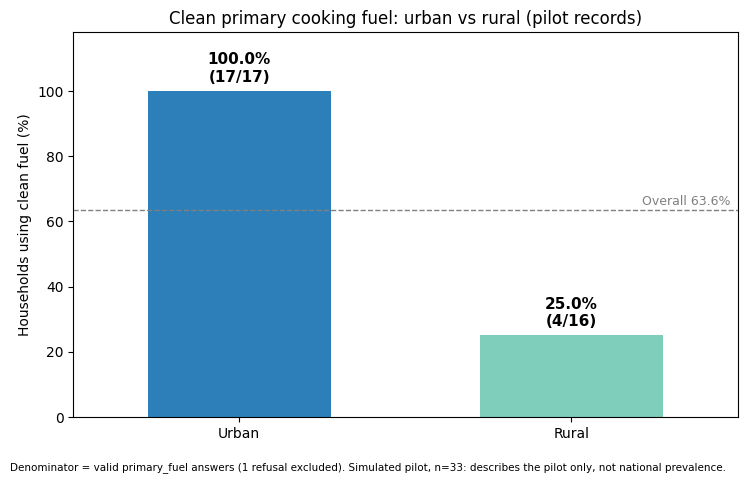

In [10]:
t1 = benchmark[(benchmark.indicator_id == "I1") & (benchmark.domain.isin(DOMAINS))].set_index("domain").loc[DOMAINS]
fig, ax = plt.subplots(figsize=(7.5, 4.8))
bars = ax.bar(["Urban", "Rural"], t1["value"], color=["#2c7fb8", "#7fcdbb"], width=0.55)
for b, (_, r) in zip(bars, t1.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, r["value"] + 2, f"{r['value']:.1f}%\n({int(r['numerator'])}/{int(r['denominator'])})",
            ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_ylim(0, 118)
ax.set_ylabel("Households using clean fuel (%)")
ax.set_title("Clean primary cooking fuel: urban vs rural (pilot records)", fontsize=12)
all_row = benchmark[(benchmark.indicator_id == "I1") & (benchmark.domain == "Overall")].iloc[0]
ax.axhline(all_row["value"], color="grey", ls="--", lw=1)
ax.text(1.48, all_row["value"] + 1.5, f"Overall {all_row['value']:.1f}%", ha="right", fontsize=9, color="grey")
ax.set_xlim(-0.5, 1.5)
fig.text(0.01, 0.01, "Denominator = valid primary_fuel answers (1 refusal excluded). Simulated pilot, n=33: describes the pilot only, "
         "not national prevalence.", fontsize=7.5, ha="left")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIG / "fig1_clean_fuel_by_domain.png", dpi=200)
plt.show()

Fuel mix by domain

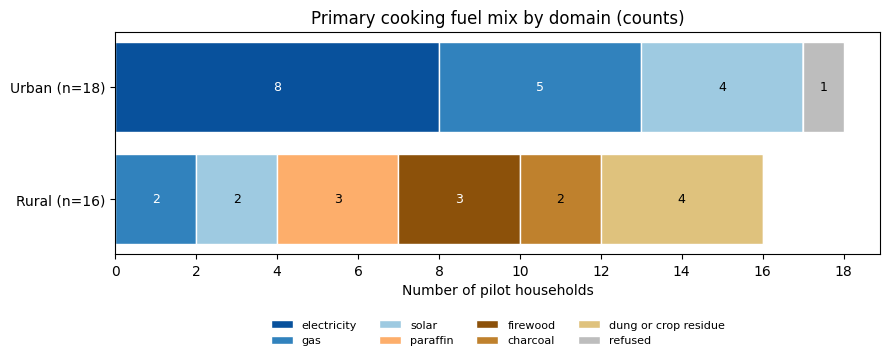

In [11]:
fuel_order = ["electricity", "gas", "solar", "paraffin", "firewood", "charcoal", "dung_or_crop_residue", "refused"]
colors = ["#08519c", "#3182bd", "#9ecae1", "#fdae6b", "#8c510a", "#bf812d", "#dfc27d", "#bdbdbd"]
ct = pd.crosstab(cases["domain"], cases["primary_fuel"]).reindex(index=DOMAINS, columns=fuel_order, fill_value=0)
fig, ax = plt.subplots(figsize=(9, 3.9))
left = np.zeros(len(ct))
for f, c in zip(fuel_order, colors):
    ax.barh(["Urban (n=%d)" % ct.loc["urban"].sum(), "Rural (n=%d)" % ct.loc["rural"].sum()], ct[f], left=left, color=c,
            label=f.replace("_", " "), edgecolor="white")
    for i, v in enumerate(ct[f]):
        if v > 0:
            ax.text(left[i] + v / 2, i, str(v), ha="center", va="center", fontsize=9,
                    color="white" if f in ("electricity", "gas", "firewood") else "black")
    left += ct[f].values
ax.set_xlabel("Number of pilot households")
ax.set_title("Primary cooking fuel mix by domain (counts)", fontsize=12)
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
ax.invert_yaxis()
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
fig.tight_layout()
fig.savefig(FIG / "fig2_fuel_mix_by_domain.png", dpi=200)
plt.show()

Expenditure by domain

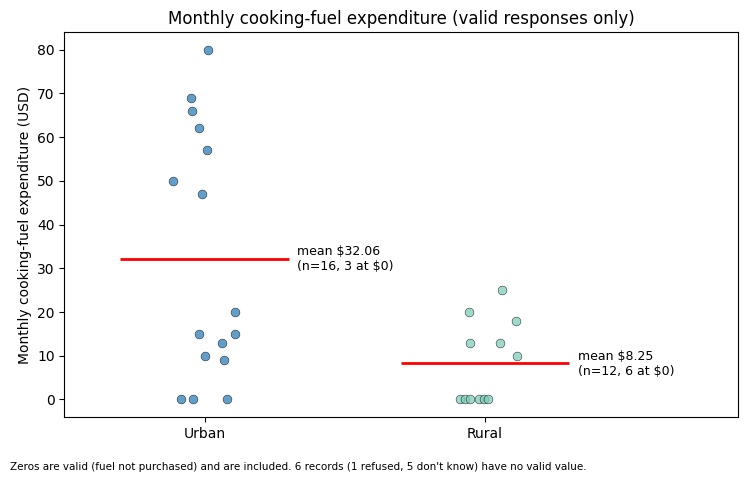

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
rng = np.random.default_rng(1)
for i, dom in enumerate(DOMAINS):
    v = cases.loc[cases["domain"] == dom, "exp_value_valid"].dropna()
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(v)), v, s=40, alpha=0.75, color=["#2c7fb8", "#7fcdbb"][i], edgecolor="k", lw=0.4)
    ax.hlines(v.mean(), i - 0.3, i + 0.3, color="red", lw=2)
    ax.text(i + 0.33, v.mean(), f"mean ${v.mean():.2f}\n(n={len(v)}, {int((v == 0).sum())} at $0)", va="center", fontsize=9)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Urban", "Rural"])
ax.set_xlim(-0.5, 1.9)
ax.set_ylabel("Monthly cooking-fuel expenditure (USD)")
ax.set_title("Monthly cooking-fuel expenditure (valid responses only)", fontsize=12)
fig.text(0.01, 0.01, "Zeros are valid (fuel not purchased) and are included. 6 records (1 refused, 5 don't know) have no valid value.",
         fontsize=7.5)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIG / "fig3_expenditure_by_domain.png", dpi=200)
plt.show()

Weighting demonstration: build simulated frame

In [13]:
rng = np.random.default_rng(206)          # fixed seed: the demonstration is reproducible

def make_stratum(name, n_ea, size_lo, size_hi, p_mean, p_sd):
    sizes = rng.integers(size_lo, size_hi, n_ea)
    p_ea = np.clip(rng.normal(p_mean, p_sd, n_ea), 0.02, 0.98)
    return pd.DataFrame({"stratum": name, "ea": [f"{name[0].upper()}{i + 1:02d}" for i in range(n_ea)],
                         "M": sizes, "p_ea": p_ea})

frame = pd.concat([make_stratum("urban", 30, 90, 190, 0.85, 0.07),
                   make_stratum("rural", 70, 60, 160, 0.20, 0.10)], ignore_index=True)

# Full simulated population of households (so the true value is known)
pop = frame.loc[frame.index.repeat(frame["M"])].reset_index(drop=True)
pop["clean"] = rng.binomial(1, pop["p_ea"])
TRUE_P = pop["clean"].mean()
print(f"Simulated population: {len(pop):,} households in {len(frame)} EAs; TRUE clean-fuel proportion = {TRUE_P:.3f}")
display(frame.groupby("stratum").agg(EAs=("ea", "count"), households=("M", "sum")))

Simulated population: 12,194 households in 100 EAs; TRUE clean-fuel proportion = 0.436


,EAs,households
stratum,,
rural,70,7727
urban,30,4467


Weighting demonstration: draw one sample

In [14]:
N_EA, N_HH = 6, 12
ea_codes = frame["ea"].tolist()
ea_rows = {e: np.flatnonzero(pop["ea"].to_numpy() == e) for e in ea_codes}   # household row numbers per EA
frame_by_stratum = {st: g.reset_index(drop=True) for st, g in frame.groupby("stratum")}
y_pop = pop["clean"].to_numpy()

def pps_systematic(df, n, gen):
    """Systematic probability-proportional-to-size selection of n EAs; returns selected EAs with P(EA selected)."""
    df = df.iloc[gen.permutation(len(df))].reset_index(drop=True)   # random order before systematic selection
    total = df["M"].sum()
    interval = total / n
    points = gen.uniform(0, interval) + interval * np.arange(n)
    idx = np.searchsorted(df["M"].cumsum().to_numpy(), points, side="right")
    sel = df.iloc[idx].copy()
    sel["p_ea_selected"] = n * sel["M"] / total                     # first-stage inclusion probability
    return sel

def draw_sample(gen):
    parts = []
    for st, g in frame_by_stratum.items():
        for _, e in pps_systematic(g, N_EA, gen).iterrows():
            rows = gen.choice(ea_rows[e["ea"]], N_HH, replace=False)                 # second stage: SRS of households
            parts.append(pd.DataFrame({"stratum": st, "ea": e["ea"], "M": e["M"], "clean": y_pop[rows],
                                       "p_ea_selected": e["p_ea_selected"], "p_hh_given_ea": N_HH / e["M"]}))
    smp = pd.concat(parts, ignore_index=True)
    smp["pi"] = smp["p_ea_selected"] * smp["p_hh_given_ea"]            # overall inclusion probability
    smp["base_weight"] = 1 / smp["pi"]                                   # base (design) weight
    return smp

def estimate(smp):
    y, w = smp["clean"].to_numpy(), smp["base_weight"].to_numpy()
    n, Wtot = len(smp), w.sum()
    p_unw, p_w = y.mean(), (w * y).sum() / Wtot
    se_srs = np.sqrt(p_unw * (1 - p_unw) / n)                           # naive: unweighted, SRS formula
    var_strat, var_num = 0.0, 0.0
    z = w * (y - p_w)
    for st, g in smp.groupby("stratum"):
        Wh, ph = g["base_weight"].sum() / Wtot, g["clean"].mean()
        var_strat += Wh ** 2 * ph * (1 - ph) / len(g)                   # weighted, stratified, households independent
        zc = pd.Series(z[g.index]).groupby(g["ea"].to_numpy()).sum()
        k = len(zc)
        var_num += k / (k - 1) * ((zc - zc.mean()) ** 2).sum()          # ultimate-cluster variance (EAs = PSUs)
    return dict(p_unw=p_unw, p_w=p_w, se_srs=se_srs, se_strat=np.sqrt(var_strat), se_des=np.sqrt(var_num) / Wtot)

smp = draw_sample(rng)
print("Inclusion probabilities and base weights (one row per selected EA):")
display(smp.groupby(["stratum", "ea"]).agg(M=("M", "first"), P_EA=("p_ea_selected", "first"), P_HH_given_EA=("p_hh_given_ea", "first"),
                                          pi=("pi", "first"), base_weight=("base_weight", "first"), sampled_hh=("clean", "size"),
                                          clean_in_sample=("clean", "sum")).round(4))
print(f"\nSum of base weights = {smp['base_weight'].sum():,.0f}   (simulated population size = {len(pop):,})")
smp.groupby(["stratum", "ea"]).agg(M=("M", "first"), P_EA=("p_ea_selected", "first"), P_HH_given_EA=("p_hh_given_ea", "first"),
                                   pi=("pi", "first"), base_weight=("base_weight", "first")).round(5).to_csv(OUT / "weighting_demo_weights.csv")

Inclusion probabilities and base weights (one row per selected EA):


M    P_EA  P_HH_given_EA      pi  base_weight  sampled_hh  clean_in_sample
stratum ea                                                                               
rural   R07  132  0.1025         0.0909  0.0093     107.3194          12                3
        R12  110  0.0854         0.1091  0.0093     107.3194          12                3
        R28  157  0.1219         0.0764  0.0093     107.3194          12                5
        R40  139  0.1079         0.0863  0.0093     107.3194          12                4
        R69   76  0.0590         0.1579  0.0093     107.3194          12                3
        R70   83  0.0644         0.1446  0.0093     107.3194          12                2
urban   U12  100  0.1343         0.1200  0.0161      62.0417          12               11
        U14  174  0.2337         0.0690  0.0161      62.0417          12                8
        U21  121  0.1625         0.0992  0.0161      62.0417          12                9
        U25  127  0.1706         0.0945  0.0161      62.0417          12                8
        U27  165  0.2216         0.0727  0.0161      62.0417          12                9
        U30  172  0.2310         0.0698  0.0161      62.0417          12               10


Sum of base weights = 12,194   (simulated population size = 12,194)
